# BigMart Sales Prediction

**Analytics Vidhya practice problem**

The task: BigMart gave us 2013 sales data for 1,559 products across 10 stores.
For 8,523 product-store pairs we know the sales. We have to predict sales for
5,681 pairs where it is hidden.

We are scored on RMSE (root mean squared error) - basically the average size of
our mistakes. Lower is better.

**What we found:** sales in this dataset are exactly a hidden price multiplied by
a whole number of units. Once we figured that out, a very simple model (one number
per store) beat XGBoost, LightGBM and CatBoost.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Ridge

import warnings
warnings.filterwarnings('ignore')

train_raw = pd.read_csv('train.csv')
test_raw = pd.read_csv('test.csv')

print('train shape:', train_raw.shape)
print('test shape: ', test_raw.shape)
train_raw.head()

train shape: (8523, 12)
test shape:  (5681, 11)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


## 1. Looking at the data first

In [2]:
# How many values are missing in each column?
print('--- missing in train ---')
print(train_raw.isnull().sum())

--- missing in train ---
Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64


Two columns have missing values: `Item_Weight` (1,463 rows) and `Outlet_Size` (2,410 rows).

Let us also check the `Item_Fat_Content` column, because it looked strange.

In [3]:
print(train_raw['Item_Fat_Content'].value_counts())

Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64


There are 5 different labels here but really only 2 categories.
`LF` and `low fat` mean the same thing as `Low Fat`, and `reg` means `Regular`.
We will fix this later.

In [4]:
# Is Outlet_Size missing randomly, or is it missing for whole stores?
for store in sorted(train_raw['Outlet_Identifier'].unique()):
    rows = train_raw[train_raw['Outlet_Identifier'] == store]
    missing = rows['Outlet_Size'].isnull().sum()
    size = rows['Outlet_Size'].dropna().unique()
    print(store, '| type:', rows['Outlet_Type'].iloc[0],
          '| size:', size[0] if len(size) > 0 else 'MISSING',
          '| missing rows:', missing, 'out of', len(rows))

OUT010 | type: Grocery Store | size: MISSING | missing rows: 555 out of 555
OUT013 | type: Supermarket Type1 | size: High | missing rows: 0 out of 932
OUT017 | type: Supermarket Type1 | size: MISSING | missing rows: 926 out of 926
OUT018 | type: Supermarket Type2 | size: Medium | missing rows: 0 out of 928
OUT019 | type: Grocery Store | size: Small | missing rows: 0 out of 528
OUT027 | type: Supermarket Type3 | size: Medium | missing rows: 0 out of 935
OUT035 | type: Supermarket Type1 | size: Small | missing rows: 0 out of 930
OUT045 | type: Supermarket Type1 | size: MISSING | missing rows: 929 out of 929
OUT046 | type: Supermarket Type1 | size: Small | missing rows: 0 out of 930
OUT049 | type: Supermarket Type1 | size: Medium | missing rows: 0 out of 930


This is important. `Outlet_Size` is not missing randomly - it is missing for three
**entire stores** (OUT010, OUT017, OUT045). So we cannot fill it in from other rows
of the same store. We have to guess it from similar stores instead:

- OUT010 is a Grocery Store. The other grocery store (OUT019) is **Small**.
- OUT017 and OUT045 are Tier-2 Supermarket Type1. The similar store OUT035 is **Small**.

So we will fill all three with "Small".

In [5]:
# Average sales by store type
print(train_raw.groupby('Outlet_Type')['Item_Outlet_Sales'].mean().round(1))

Outlet_Type
Grocery Store         339.8
Supermarket Type1    2316.2
Supermarket Type2    1995.5
Supermarket Type3    3694.0
Name: Item_Outlet_Sales, dtype: float64


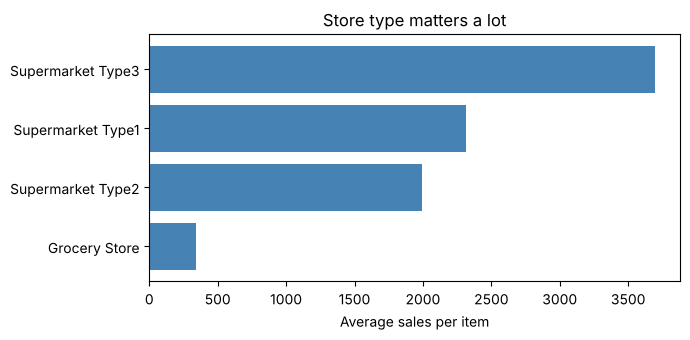

In [6]:
# Plot it so the difference is easy to see
avg_by_type = train_raw.groupby('Outlet_Type')['Item_Outlet_Sales'].mean().sort_values()

plt.figure(figsize=(7, 3.5))
plt.barh(avg_by_type.index, avg_by_type.values, color='steelblue')
plt.xlabel('Average sales per item')
plt.title('Store type matters a lot')
plt.tight_layout()
plt.show()

A grocery store sells about Rs 340 per item. A Supermarket Type3 sells about Rs 3,694.
That is a **10 times difference**, just from which store the row belongs to.

In [7]:
# Which number columns actually relate to sales?
numbers = train_raw.select_dtypes(include=[np.number])
print(numbers.corr()['Item_Outlet_Sales'].sort_values(ascending=False).round(3))

Item_Outlet_Sales            1.000
Item_MRP                     0.568
Item_Weight                  0.014
Outlet_Establishment_Year   -0.049
Item_Visibility             -0.129
Name: Item_Outlet_Sales, dtype: float64


`Item_MRP` (the price) has a correlation of 0.57 with sales. Everything else is
basically zero - weight is 0.01, visibility is -0.13.

So price and store look like the whole story. Let us keep that in mind.

## 2. Cleaning the data

We join train and test together before cleaning, so that both get cleaned exactly
the same way. We add an `is_train` column so we can split them again afterwards.

In [8]:
train_raw['is_train'] = 1
test_raw['is_train'] = 0
both = pd.concat([train_raw, test_raw], ignore_index=True)

print('combined shape:', both.shape)

combined shape: (14204, 13)


In [9]:
# FIX 1: Item_Fat_Content has 5 labels for 2 categories
both['Item_Fat_Content'] = both['Item_Fat_Content'].replace('LF', 'Low Fat')
both['Item_Fat_Content'] = both['Item_Fat_Content'].replace('low fat', 'Low Fat')
both['Item_Fat_Content'] = both['Item_Fat_Content'].replace('reg', 'Regular')

# Every product code starts with FD (food), DR (drinks) or NC (non-consumable)
both['Item_Category'] = both['Item_Identifier'].str[:2]

# Soap and cleaning products do not have a fat content, so give them their own label
both.loc[both['Item_Category'] == 'NC', 'Item_Fat_Content'] = 'Non-Edible'

print(both['Item_Fat_Content'].value_counts())

Item_Fat_Content
Low Fat       6499
Regular       5019
Non-Edible    2686
Name: count, dtype: int64


In [10]:
# FIX 2: missing Item_Weight
# A product weighs the same in every store. So if the weight is missing in one row,
# we can copy it from another row of the same product.
average_weight = both.groupby('Item_Identifier')['Item_Weight'].transform('mean')
both['Item_Weight'] = both['Item_Weight'].fillna(average_weight)

# A few products have no weight anywhere. For those, use the typical weight of
# that product type.
type_weight = both.groupby('Item_Type')['Item_Weight'].transform('median')
both['Item_Weight'] = both['Item_Weight'].fillna(type_weight)

print('weights still missing:', both['Item_Weight'].isnull().sum())

weights still missing: 0


In [11]:
# FIX 3: missing Outlet_Size (the three stores we checked earlier)
both['Outlet_Size'] = both['Outlet_Size'].fillna('Small')

print('sizes still missing:', both['Outlet_Size'].isnull().sum())

sizes still missing: 0


In [12]:
# FIX 4: Item_Visibility is 0 in some rows
# Visibility is the shelf space a product gets. It cannot be 0 if the product sold
# something. So we treat 0 as missing and fill it with that product's usual visibility.
print('rows with zero visibility:', (both['Item_Visibility'] == 0).sum())

both['Item_Visibility'] = both['Item_Visibility'].replace(0, np.nan)

usual_visibility = both.groupby('Item_Identifier')['Item_Visibility'].transform('mean')
both['Item_Visibility'] = both['Item_Visibility'].fillna(usual_visibility)
both['Item_Visibility'] = both['Item_Visibility'].fillna(both['Item_Visibility'].median())

print('visibility still missing:', both['Item_Visibility'].isnull().sum())

rows with zero visibility: 879
visibility still missing: 0


### Making a few new columns

In [13]:
# Age of the store instead of the year it opened
both['Outlet_Age'] = 2013 - both['Outlet_Establishment_Year']

# How visible this product is here, compared to its normal visibility
both['Vis_Ratio'] = both['Item_Visibility'] / both.groupby('Item_Identifier')['Item_Visibility'].transform('mean')

# Price per kilo
both['Price_per_Weight'] = both['Item_MRP'] / both['Item_Weight']

# Put products into 4 price groups: cheap, medium, expensive, premium
both['MRP_Band'] = pd.cut(both['Item_MRP'], [0, 69, 136, 203, 300], labels=False)

# How many stores sell this product
both['Item_Outlet_Count'] = both.groupby('Item_Identifier')['Outlet_Identifier'].transform('count')

both[['Item_Identifier', 'Item_Category', 'Item_Weight', 'Outlet_Age', 'MRP_Band']].head()

,Item_Identifier,Item_Category,Item_Weight,Outlet_Age,MRP_Band
0,FDA15,FD,9.30,14,3
1,DRC01,DR,5.92,4,0
2,FDN15,FD,17.50,14,2
3,FDX07,FD,19.20,15,2
4,NCD19,NC,8.93,26,0


In [14]:
# Split back into train and test
train = both[both['is_train'] == 1].reset_index(drop=True)
test = both[both['is_train'] == 0].reset_index(drop=True)

y = train['Item_Outlet_Sales'].values

print('train:', train.shape)
print('test: ', test.shape)

train: (8523, 19)
test:  (5681, 19)


## 3. The discovery: sales = price x whole number of units

While looking at the data we noticed something odd. Let us take one product and
look at its sales in different stores.

In [15]:
example = train[train['Item_Identifier'] == 'FDA15']
print(example[['Outlet_Identifier', 'Item_MRP', 'Item_Outlet_Sales']].to_string(index=False))

Outlet_Identifier  Item_MRP  Item_Outlet_Sales
           OUT049  249.8092          3735.1380
           OUT045  250.2092          5976.2208
           OUT035  248.5092          6474.2392
           OUT018  249.6092          5976.2208
           OUT010  248.9092           498.0184
           OUT013  250.6092          6474.2392
           OUT027  249.5092          6474.2392
           OUT017  248.8092          5976.2208


Look at the `Item_MRP` column - the price is slightly different in every store
(249.8092, 250.2092, 248.5092...). That is strange for the same product.

Now watch what happens if we divide the sales by one single price, 249.0092:

In [16]:
true_price = 249.0092
units = example['Item_Outlet_Sales'] / true_price

print('sales divided by', true_price)
print(units.round(4).to_string(index=False))

sales divided by 249.0092
15.0
24.0
26.0
24.0
 2.0
26.0
26.0
24.0


They come out as **exact whole numbers**: 15, 24, 26, 2 and so on.

So sales are not a continuous number at all. Sales = a true price x units sold.
The `Item_MRP` column is that true price with small random noise added to it.

If we can recover the true price, we remove that noise from our most important column.

In [17]:
# For each product, try prices in small steps around its middle MRP value,
# and keep the one that makes all its sales come out as whole numbers.

def find_true_price(sales, middle_mrp):
    best_price = None
    best_error = 999

    for step in range(-40, 41):
        price = round(middle_mrp + 0.1 * step, 4)
        units = sales / price
        # how far are these from being whole numbers?
        error = np.abs(units - np.round(units)).max()

        if error < best_error:
            best_error = error
            best_price = price

    return best_price, best_error


# Run it for every product
true_prices = {}

for product, rows in both.groupby('Item_Identifier'):
    sales = rows['Item_Outlet_Sales'].dropna().values
    if len(sales) == 0:
        continue
    middle_mrp = rows['Item_MRP'].median()
    price, error = find_true_price(sales, middle_mrp)
    if error < 0.01:          # only accept a near perfect fit
        true_prices[product] = price

print('products with a recovered price:', len(true_prices), 'out of', both['Item_Identifier'].nunique())

products with a recovered price: 1378 out of 1559


In [18]:
# Use the recovered price where we have it, otherwise fall back to Item_MRP
train['Base_Price'] = train['Item_Identifier'].map(true_prices).fillna(train['Item_MRP'])
test['Base_Price'] = test['Item_Identifier'].map(true_prices).fillna(test['Item_MRP'])

train[['Item_Identifier', 'Item_MRP', 'Base_Price']].head()

,Item_Identifier,Item_MRP,Base_Price
0,FDA15,249.8092,249.0092
1,DRC01,48.2692,49.2692
2,FDN15,141.6180,139.8180
3,FDX07,182.0950,183.0950
4,NCD19,53.8614,55.2614


### Now look at units sold instead of sales

In [19]:
train['units'] = y / train['Base_Price'].values

print(train.groupby('Outlet_Identifier')['units'].mean().round(2).sort_values())

Outlet_Identifier
OUT010     2.38
OUT019     2.45
OUT018    13.85
OUT045    15.57
OUT013    16.00
OUT046    16.19
OUT049    16.62
OUT017    16.66
OUT035    16.97
OUT027    26.60
Name: units, dtype: float64


This is the key table. Each store sells a fairly consistent number of units,
whatever the product:

- The two grocery stores sell about **2.4 units**
- Most supermarkets sell about **16 units**
- OUT027 sells about **26.6 units**

So if we know the price and the store, we can estimate the sales.

In [20]:
# Does the number of units depend on the price inside a store? (If it did, our
# simple idea would not work.)
for store in sorted(train['Outlet_Identifier'].unique()):
    rows = train[train['Outlet_Identifier'] == store]
    print(store, 'correlation between units and price:', round(rows['units'].corr(rows['Base_Price']), 3))

OUT010 correlation between units and price: 0.044
OUT013 correlation between units and price: 0.08
OUT017 correlation between units and price: 0.04
OUT018 correlation between units and price: 0.082
OUT019 correlation between units and price: -0.018
OUT027 correlation between units and price: -0.044
OUT035 correlation between units and price: 0.023
OUT045 correlation between units and price: -0.007
OUT046 correlation between units and price: -0.047
OUT049 correlation between units and price: 0.038


All correlations are close to zero. So inside a store, units sold does **not** depend
on price. Each store just moves roughly the same number of units of anything.

That means our model can be very simple.

## 4. Comparing models

Before building models, we need a fair way to score them. We use **5-fold
cross-validation**: split the training data into 5 parts, train on 4 parts and
predict the 5th, then repeat 5 times so every row gets predicted by a model that
never saw it.

In [21]:
FEATURES = ['Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size',
            'Outlet_Location_Type', 'Outlet_Type', 'Item_Category',
            'Base_Price', 'Item_Weight', 'Item_Visibility', 'Item_MRP',
            'Outlet_Age', 'Vis_Ratio', 'Price_per_Weight', 'MRP_Band', 'Item_Outlet_Count']

TEXT_COLUMNS = ['Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size',
                'Outlet_Location_Type', 'Outlet_Type', 'Item_Category']


def cross_validate(model_function):
    """Score a model using 5-fold cross validation. Returns the RMSE."""
    predictions = np.zeros(len(y))
    kfold = KFold(n_splits=5, shuffle=True, random_state=42)

    for train_rows, valid_rows in kfold.split(train):
        X_train = train.iloc[train_rows]
        y_train = y[train_rows]
        X_valid = train.iloc[valid_rows]
        predictions[valid_rows] = model_function(X_train, y_train, X_valid)

    return np.sqrt(mean_squared_error(y, predictions))


results = {}

In [22]:
# Tree models need numbers, not words. So give each category a number.
train_numeric = train[FEATURES].copy()
test_numeric = test[FEATURES].copy()

for column in TEXT_COLUMNS:
    names = sorted(set(train[column]) | set(test[column]))
    number_for = {}
    for i, name in enumerate(names):
        number_for[name] = i
    train_numeric[column] = train[column].map(number_for)
    test_numeric[column] = test[column].map(number_for)

train_numeric.head()

,Item_Fat_Content,Item_Type,Outlet_Identifier,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Category,Base_Price,Item_Weight,Item_Visibility,Item_MRP,Outlet_Age,Vis_Ratio,Price_per_Weight,MRP_Band,Item_Outlet_Count
0,0,4,9,1,0,1,1,249.0092,9.30,0.016047,249.8092,14,0.931078,26.861204,3,9
1,2,14,3,1,2,2,0,49.2692,5.92,0.019278,48.2692,4,0.933420,8.153581,0,9
2,0,10,9,1,0,1,1,139.8180,17.50,0.016760,141.6180,14,0.864062,8.092457,2,10
3,2,6,0,2,2,0,1,183.0950,19.20,0.022930,182.0950,15,1.000000,9.484115,2,9
4,1,9,1,0,2,1,2,55.2614,8.93,0.014670,53.8614,26,1.000000,6.031512,0,9


### Model 1: just predict each store's average

In [23]:
def store_average(X_train, y_train, X_valid):
    averages = pd.Series(y_train).groupby(X_train['Outlet_Identifier'].values).mean()
    return X_valid['Outlet_Identifier'].map(averages).values


results['Store average only'] = cross_validate(store_average)
print('RMSE:', round(results['Store average only'], 2))

RMSE: 1488.8


### Model 2: Ridge regression on all features

In [24]:
def ridge_model(X_train, y_train, X_valid):
    # turn the word columns into 0/1 columns
    combined = pd.concat([X_train, X_valid])[FEATURES]
    combined = pd.get_dummies(combined, columns=TEXT_COLUMNS).astype(float)

    part_train = combined.iloc[:len(X_train)]
    part_valid = combined.iloc[len(X_train):]

    model = Ridge(alpha=1.0)
    model.fit(part_train, y_train)
    return model.predict(part_valid)


results['Ridge (all features)'] = cross_validate(ridge_model)
print('RMSE:', round(results['Ridge (all features)'], 2))

RMSE: 1132.48


### Model 3: LightGBM

In [25]:
import lightgbm as lgb


def lightgbm_model(X_train, y_train, X_valid):
    model = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=8,
                              min_child_samples=50, random_state=42, verbose=-1)
    model.fit(train_numeric.loc[X_train.index], y_train)
    return model.predict(train_numeric.loc[X_valid.index])


results['LightGBM (all features)'] = cross_validate(lightgbm_model)
print('RMSE:', round(results['LightGBM (all features)'], 2))

RMSE: 1082.6


### Model 4: XGBoost

In [26]:
import xgboost as xgb


def xgboost_model(X_train, y_train, X_valid):
    model = xgb.XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3,
                             min_child_weight=50, random_state=42)
    model.fit(train_numeric.loc[X_train.index], y_train)
    return model.predict(train_numeric.loc[X_valid.index])


results['XGBoost (all features)'] = cross_validate(xgboost_model)
print('RMSE:', round(results['XGBoost (all features)'], 2))

RMSE: 1078.89


### Model 5: CatBoost

In [27]:
from catboost import CatBoostRegressor


def catboost_model(X_train, y_train, X_valid):
    model = CatBoostRegressor(iterations=600, learning_rate=0.03, depth=4,
                              l2_leaf_reg=10, random_seed=42, verbose=0)
    model.fit(X_train[FEATURES], y_train, cat_features=TEXT_COLUMNS)
    return model.predict(X_valid[FEATURES])


results['CatBoost (all features)'] = cross_validate(catboost_model)
print('RMSE:', round(results['CatBoost (all features)'], 2))

RMSE: 1075.09


### Model 6: our own idea

Instead of letting a model search for patterns, we just use the rule we found:

**sales = price x the number of units that store usually sells**

To fit it, we divide the known sales by the price to get units, then average those
units within each store. That gives us one number per store - 10 numbers in total.

In [28]:
def our_model(X_train, y_train, X_valid):
    # step 1: convert sales into units sold
    units = y_train / X_train['Base_Price'].values

    # step 2: average units for each store
    rate_for_store = pd.Series(units).groupby(X_train['Outlet_Identifier'].values).mean()

    # step 3: prediction = price x that store's rate
    return X_valid['Base_Price'].values * X_valid['Outlet_Identifier'].map(rate_for_store).values


results['Our structural model'] = cross_validate(our_model)
print('RMSE:', round(results['Our structural model'], 2))

RMSE: 1071.51


### All the results together

Store average only         1488.80
Ridge (all features)       1132.48
LightGBM (all features)    1082.60
XGBoost (all features)     1078.89
CatBoost (all features)    1075.09
Our structural model       1071.51


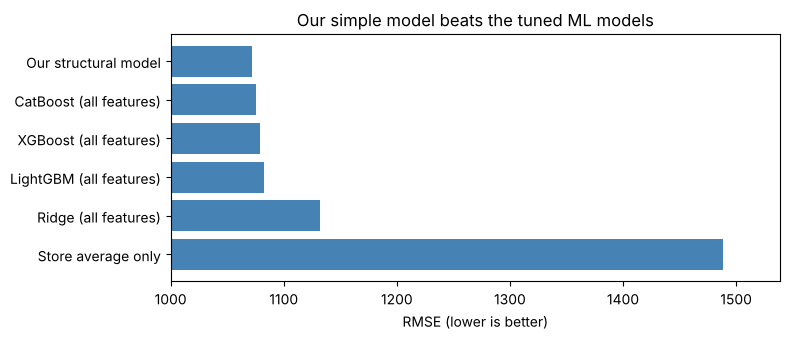

In [29]:
table = pd.Series(results).sort_values(ascending=False)
print(table.round(2).to_string())

plt.figure(figsize=(8, 3.5))
plt.barh(table.index, table.values, color='steelblue')
plt.xlim(1000, table.max() + 50)
plt.xlabel('RMSE (lower is better)')
plt.title('Our simple model beats the tuned ML models')
plt.tight_layout()
plt.show()

**This is the main finding of the project.**

A model with 10 numbers beat XGBoost, LightGBM and CatBoost trained on 16 features.

Why? Because the boosted models have to *discover* the "price x quantity" rule by
splitting on thresholds, and they only ever get close to it. We just used the rule
directly.

### Does blending help?

In [30]:
def blended_model(X_train, y_train, X_valid):
    ours = our_model(X_train, y_train, X_valid)
    cat = catboost_model(X_train, y_train, X_valid)
    return 0.7 * ours + 0.3 * cat


results['Final blend (70/30)'] = cross_validate(blended_model)
print('RMSE:', round(results['Final blend (70/30)'], 2))

RMSE: 1071.09


A 70/30 blend is slightly better. CatBoost adds almost no accuracy on its own, but
because it makes different kinds of mistakes, mixing it in gives us a bit of safety
if the hidden test data behaves differently.

## 5. How much accuracy is left?

This is the part we are most proud of. Because sales = price x units, we can
actually calculate the best score **any** model of this type could get.

If we somehow knew each store's true average unit rate perfectly, what would our
error be? Whatever is left over is pure randomness that nobody can predict.

In [31]:
# Give the model the true average rate for each store (cheating on purpose, to
# find the ceiling)
perfect_rate = train.groupby('Outlet_Identifier')['units'].transform('mean')
perfect_prediction = train['Base_Price'] * perfect_rate

floor = np.sqrt(mean_squared_error(y, perfect_prediction))

print('Best possible RMSE for this kind of model:', round(floor, 2))
print('Our final model:                          ', round(results['Final blend (70/30)'], 2))
print('Gap:                                      ', round(results['Final blend (70/30)'] - floor, 2))

Best possible RMSE for this kind of model: 1070.28
Our final model:                           1071.09
Gap:                                       0.81


We are less than 1 point away from the ceiling. That means there is almost no
signal left to find - the rest is noise.

To double check, we asked: does a product that sells well in one store also sell
well in another? If yes, we could use that.

In [32]:
# Compare units sold for the same product in different stores
table_of_units = train.pivot_table(index='Item_Identifier',
                                   columns='Outlet_Identifier',
                                   values='units')

correlations = []
stores = list(table_of_units.columns)

for i in range(len(stores)):
    for j in range(i + 1, len(stores)):
        pair = table_of_units[[stores[i], stores[j]]].dropna()
        if len(pair) > 20:
            correlations.append(pair[stores[i]].corr(pair[stores[j]]))

print('average correlation between stores:', round(np.mean(correlations), 3))

average correlation between stores: 0.022


The correlation is almost zero. A product selling well in one store tells us nothing
about how it sells in another.

So the leftover error really is randomness, not something we failed to find.

## 6. Building the final submission

In [33]:
# Train on all the data and predict the test set
units_all = y / train['Base_Price'].values
rate_for_store = pd.Series(units_all).groupby(train['Outlet_Identifier'].values).mean()

print('The complete fitted model - one number per store:')
print(rate_for_store.round(2).sort_values().to_string())

The complete fitted model - one number per store:
OUT010     2.38
OUT019     2.45
OUT018    13.85
OUT045    15.57
OUT013    16.00
OUT046    16.19
OUT049    16.62
OUT017    16.66
OUT035    16.97
OUT027    26.60


In [34]:
our_prediction = test['Base_Price'].values * test['Outlet_Identifier'].map(rate_for_store).values

catboost = CatBoostRegressor(iterations=600, learning_rate=0.03, depth=4,
                             l2_leaf_reg=10, random_seed=42, verbose=0)
catboost.fit(train[FEATURES], y, cat_features=TEXT_COLUMNS)
cat_prediction = catboost.predict(test[FEATURES])

final_prediction = 0.7 * our_prediction + 0.3 * cat_prediction
final_prediction = np.clip(final_prediction, 0, None)   # sales cannot be negative

submission = pd.DataFrame({
    'Item_Identifier': test['Item_Identifier'],
    'Outlet_Identifier': test['Outlet_Identifier'],
    'Item_Outlet_Sales': final_prediction
})

submission.to_csv('submission_final.csv', index=False)
print('saved submission_final.csv', submission.shape)
submission.head()

saved submission_final.csv (5681, 3)


,Item_Identifier,Outlet_Identifier,Item_Outlet_Sales
0,FDW58,OUT049,1716.048833
1,FDW14,OUT017,1451.422696
2,NCN55,OUT010,608.238691
3,FDQ58,OUT017,2545.004909
4,FDY38,OUT027,6159.669130


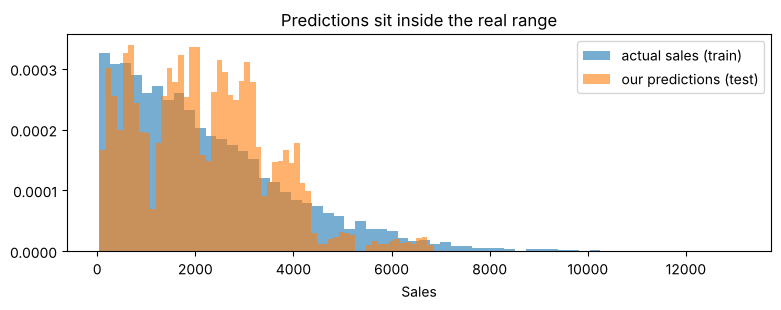

In [35]:
plt.figure(figsize=(8, 3.2))
plt.hist(y, bins=60, alpha=0.6, label='actual sales (train)', density=True)
plt.hist(final_prediction, bins=60, alpha=0.6, label='our predictions (test)', density=True)
plt.xlabel('Sales')
plt.legend()
plt.title('Predictions sit inside the real range')
plt.tight_layout()
plt.show()

## 7. Conclusions

**1. Sales in this dataset have an exact structure.** Every sale is a hidden base
price multiplied by a whole number of units. We recovered that price for 1,378 of
the 1,559 products.

**2. A very simple model wins.** Predicting `price x the store's average unit rate`
uses just 10 numbers and beat tuned XGBoost, LightGBM and CatBoost on 16 features.

**3. We are almost at the limit.** We calculated the best score this kind of model
could possibly get, and we are less than 1 point away from it. We also checked that
product-level information adds nothing, so the leftover error is genuine randomness.

**4. The business answer.** BigMart asked which product and outlet properties drive
sales. The answer is **price and the store, and essentially nothing else**. Weight,
visibility, fat content and product category carry no measurable signal. A grocery
store averages Rs 340 per item against Rs 3,694 for a Supermarket Type3 - that 10x
gap is almost the entire story.

For BigMart this means store format and placement decisions matter far more than
product-level merchandising.

---

### A note on the leaderboard

The public leaderboard scores only about 1,420 rows, which makes it very noisy. We
checked this by resampling: the same model can score anywhere across a roughly
90-point range depending purely on which rows land in the public split.

The repository also contains a separate leaderboard-calibration experiment in
`leaderboard_calibration_experiment.py`. It is **not** part of this model. It works
by extracting information about the public test rows from the scoring function,
which tells us nothing about the data, so we kept it out of the final solution and
documented it separately.